# 07 · Ensemble

**Ide dasarnya:** model dengan algoritma berbeda membuat kesalahan yang berbeda. Kalau peringkat beberapa model dirata-rata, kesalahan yang tidak sama saling meredam. Manfaatnya bergantung pada dua hal:

1. Setiap anggota harus **cukup kuat**. Anggota yang lemah menarik ensemble turun.
2. Anggota harus **cukup berbeda** (korelasi peringkat tidak terlalu dekat ke 1). Dua model yang mengurutkan nasabah hampir sama tidak saling menambal.

| Anggota | Cara kerja | Beda dari LightGBM |
|---|---|---|
| `lgbm_tuned` (notebook 06) | pohon tumbuh per daun, regularisasi kuat | pembanding |
| `xgb` (XGBoost) | pohon tumbuh per level (kedalaman 4) | sedikit; sesama GBDT |
| `cat` (CatBoost) | pohon simetris, *ordered boosting*, encoding kategori bawaan | sedang |
| `logreg` (regresi logistik) | model **linear** pada fitur yang ditransformasi ke kuantil normal + indikator null | besar; tanpa interaksi sama sekali |

**Cara menggabung:** rata-rata **peringkat** (`rank01`), bukan rata-rata probabilitas. KS hanya peduli urutan, dan skala probabilitas tiap model berbeda.

**Jebakan utama: bobot ensemble mudah *overfit*.** Kalau bobot dicari di OOF yang sama dengan yang dinilai, hasilnya selalu tampak lebih baik dari aslinya. Karena itu bobot dinilai dengan **validasi bersarang**: bobot dipilih di 4/5 baris, lalu diterapkan ke 1/5 sisanya, bergiliran. Rata-rata sederhana (bobot sama, tanpa pencarian) juga diuji sebagai pembanding yang bebas *overfitting*.

**Protokol:** semua anggota memakai fold & seed yang sama dengan `lgbm_tuned` (42, 7, 2024). Ensemble dibandingkan berpasangan per seed dengan `lgbm_tuned`, dengan aturan keputusan yang sama:
- **jelas:** Δ ≥ 0,005, semua seed naik
- **tipis:** Δ ≥ 0,002, semua seed naik
- **tidak:** selain itu

> Waktu jalan ±40–50 menit (XGBoost & CatBoost paling lama). `QUICK = True` melewati XGBoost (paling mirip LightGBM) → ±25 menit. Run anggota disimpan di `data/preds/`; dengan `REUSE = True`, run yang sudah ada dimuat ulang tanpa dilatih lagi.

In [1]:
import gc
import json
import time
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import features as F
import modeling as M

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(70)

meta = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
FEAT, CATS = meta["features"], meta["categorical"]
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()

QUICK = False
REUSE = True
MEMBERS = ["logreg", "cat"] if QUICK else ["logreg", "cat", "xgb"]

base = M.run_from_disk("lgbm_tuned", y)
SEEDS = tuple(s for s in (42, 7, 2024) if s in base["seeds"])
print(f"lgbm_tuned: {base['meta'].get('config')} | KS OOF {base['ks_oof']:.4f} | seed tersedia {base['seeds']}")
print(f"Seed untuk ensemble: {SEEDS} | anggota baru: {MEMBERS}")

lgbm_tuned: reg. kuat + extra_trees | KS OOF 0.5227 | seed tersedia [42, 7, 2024, 11, 99]
Seed untuk ensemble: (42, 7, 2024) | anggota baru: ['logreg', 'cat', 'xgb']


## 1. Latih anggota

Parameter anggota (di `modeling.py`) mengikuti pelajaran dari notebook 06, yaitu model yang cukup teregularisasi:
- **XGBoost:** kedalaman 4, `min_child_weight` 20, 40% kolom per pohon, λ 10.
- **CatBoost:** kedalaman 6, λ 10, 50% kolom per split.
- **Regresi logistik:** C = 0,05 (regularisasi L2 cukup kuat).

Semua transformasi regresi logistik (kuantil, imputasi, one-hot) di-*fit* hanya di fold latih.

In [2]:
RUNS = {"lgbm": base}
for kind in MEMBERS:
    name = f"{kind}_v1"
    if REUSE and (M.PRED_DIR / f"{name}_meta.json").exists():
        r = M.run_from_disk(name, y)
        if all(s in r["seeds"] for s in SEEDS):
            RUNS[kind] = r
            print(f"{name}: dimuat dari disk (KS OOF {r['ks_oof']:.4f})")
            continue
    t = time.time()
    RUNS[kind] = M.train_cv(kind, train, test, FEAT, CATS, seeds=SEEDS)
    M.save_run(name, train, test, RUNS[kind], extra=dict(feature_version="v1", kind=kind))
    print(f"{name}: selesai dalam {time.time() - t:.0f} detik")
    gc.collect()

[logreg] seed 42: KS OOF 0.5188  (112s)
[logreg] seed 7: KS OOF 0.5176  (208s)
[logreg] seed 2024: KS OOF 0.5164  (290s)
[logreg] KS OOF rata-rata 3 seed: 0.5186
logreg_v1: selesai dalam 291 detik
[cat] seed 42: KS OOF 0.5188  (484s)
[cat] seed 7: KS OOF 0.5172  (1025s)
[cat] seed 2024: KS OOF 0.5176  (1397s)
[cat] KS OOF rata-rata 3 seed: 0.5207
cat_v1: selesai dalam 1397 detik
[xgb] seed 42: KS OOF 0.5174  (122s)
[xgb] seed 7: KS OOF 0.5191  (254s)
[xgb] seed 2024: KS OOF 0.5216  (365s)
[xgb] KS OOF rata-rata 3 seed: 0.5220
xgb_v1: selesai dalam 365 detik


## 2. Kekuatan & keberagaman anggota

In [3]:
rows = []
for k, r in RUNS.items():
    cmp = M.compare_runs(base, r, y, SEG) if k != "lgbm" else None
    rows.append(dict(anggota=k, ks_oof_gabungan=M.ks_score(y, np.mean([r["oof_by_seed"][s] for s in SEEDS], axis=0)),
                     **{f"ks_s{s}": r["ks_by_seed"][s] for s in SEEDS},
                     delta_vs_lgbm=None if cmp is None else cmp["delta_seed_mean"]))
members = pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))
names = list(RUNS)
corr = np.corrcoef([M.rank01(RUNS[k]["oof_by_seed"][SEEDS[0]]) for k in names])
members

anggota,ks_oof_gabungan,ks_s42,ks_s7,ks_s2024,delta_vs_lgbm
str,f64,f64,f64,f64,f64
"""lgbm""",0.5238,0.5219,0.5187,0.5217,null
"""logreg""",0.5186,0.5188,0.5176,0.5164,-0.0032
"""cat""",0.5207,0.5188,0.5172,0.5176,-0.0029
"""xgb""",0.522,0.5174,0.5191,0.5216,-0.0014


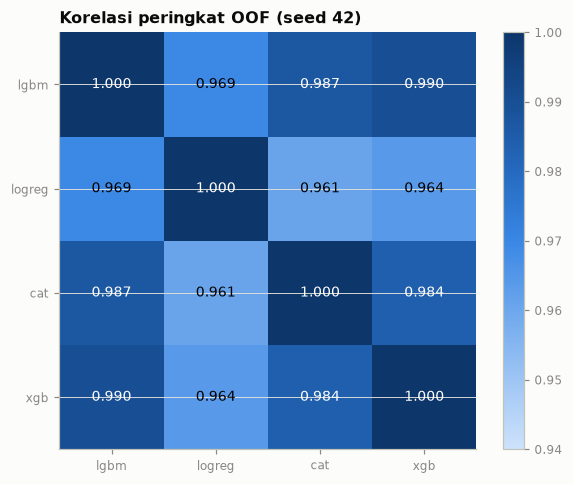

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap=E.SEQ_CMAP, vmin=min(0.94, corr.min()), vmax=1)
ax.set_xticks(range(len(names)), names); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{corr[i, j]:.3f}", ha="center", va="center", fontsize=9,
                color="white" if corr[i, j] > (corr.min() + 1) / 2 else "black")
ax.set_title(f"Korelasi peringkat OOF (seed {SEEDS[0]})", loc="left")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

**Cara membaca:**

- **KS anggota:** anggota yang jauh lebih lemah dari `lgbm` hanya berguna kalau sangat berbeda.
- **Korelasi peringkat:** 0,99 berarti dua model mengurutkan nasabah hampir identik, jadi gabungannya hampir tidak menambah apa-apa. Sesama GBDT biasanya sangat mirip. Regresi logistik paling berbeda karena tidak memodelkan interaksi sama sekali.
- **Kalau regresi logistik hampir sekuat GBDT,** hubungan fitur → risiko di data ini sebagian besar **aditif dan monoton**. Ini menjelaskan kenapa pohon kecil teregularisasi menang di notebook 06: interaksi rumit tidak banyak dibutuhkan.

## 3. Rata-rata sederhana (bobot sama)

Tanpa pencarian bobot, jadi hasilnya tidak bisa *overfit* ke OOF.

In [5]:
BLENDS, CMP = {}, {}
others = [k for k in RUNS if k != "lgbm"]
for k in others:
    BLENDS[f"lgbm + {k}"] = M.blend({"lgbm": base, k: RUNS[k]}, y, seeds=SEEDS)
BLENDS["semua (bobot sama)"] = M.blend(RUNS, y, seeds=SEEDS)
for n, b in BLENDS.items():
    CMP[n] = M.compare_runs(base, b, y, SEG)

def tbl(keys):
    return pl.DataFrame([dict(ensemble=n, delta_oof=CMP[n]["delta_oof"],
                              **{f"d_s{s}": d for s, d in zip(CMP[n]["per_seed"]["seed"], CMP[n]["per_seed"]["delta"])},
                              delta_rata2=CMP[n]["delta_seed_mean"], seed_naik=f"{CMP[n]['n_seed_positive']}/{len(SEEDS)}",
                              keputusan=M.verdict(CMP[n], noise=0.0015)) for n in keys]).with_columns(pl.col(pl.Float64).round(4))
tbl(list(BLENDS))

ensemble,delta_oof,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""lgbm + logreg""",-0.0001,0.001,0.0044,0.0008,0.002,"""3/3""","""tipis"""
"""lgbm + cat""",-0.0007,-0.0002,0.0022,-0.0005,0.0005,"""1/3""","""tidak"""
"""lgbm + xgb""",-0.0001,-0.0014,0.0013,0.0012,0.0004,"""2/3""","""tidak"""
"""semua (bobot sama)""",0.0016,0.0021,0.0053,0.0013,0.0029,"""3/3""","""tipis"""


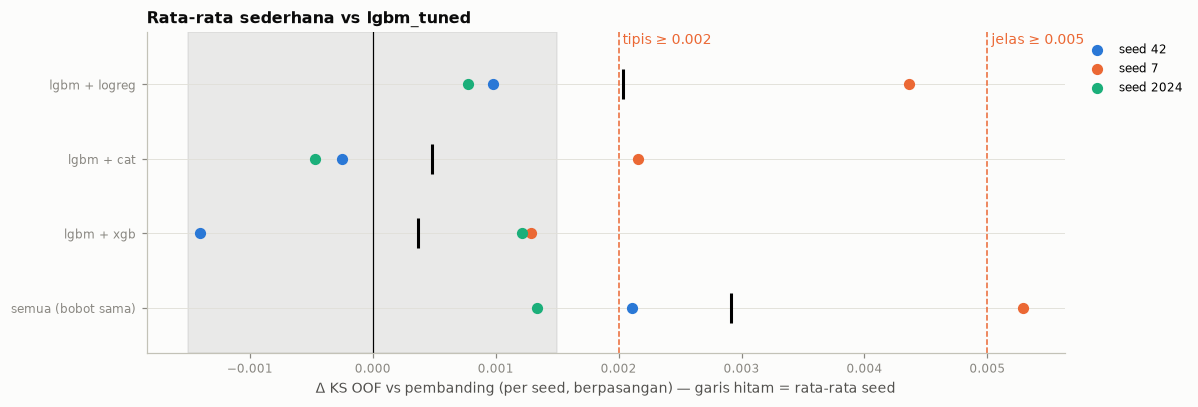

In [6]:
M.plot_paired_deltas(CMP, list(BLENDS), noise=0.0015, title="Rata-rata sederhana vs lgbm_tuned")

## 4. Bobot optimal: tampak vs jujur

- **"Tampak":** bobot terbaik dicari langsung di OOF yang sama dengan yang dinilai. Ini yang biasanya dilaporkan, padahal optimistis.
- **"Jujur" (bersarang):** bobot dicari di 4/5 baris lalu diterapkan ke 1/5 sisanya, bergiliran, untuk setiap seed.

Grid bobot: kelipatan 0,1, dengan `lgbm` minimal 0,3.

In [7]:
t = time.time()
W_IN, ks_in = M.best_weights(RUNS, y, "lgbm", list(SEEDS))
BLENDS["bobot optimal (tampak)"] = M.blend(RUNS, y, weights=W_IN, seeds=SEEDS)
CMP["bobot optimal (tampak)"] = M.compare_runs(base, BLENDS["bobot optimal (tampak)"], y, SEG)
BLENDS["bobot optimal (jujur)"] = NESTED = M.nested_blend(RUNS, y, "lgbm", seeds=SEEDS)
CMP["bobot optimal (jujur)"] = M.compare_runs(base, NESTED, y, SEG)
print(f"Bobot optimal di seluruh OOF: {W_IN} ({time.time() - t:.0f} detik)")
tbl(["bobot optimal (tampak)", "bobot optimal (jujur)"])

Bobot optimal di seluruh OOF: {'lgbm': np.float64(0.3), 'logreg': np.float64(0.3), 'cat': np.float64(0.2), 'xgb': np.float64(0.2)} (20 detik)


ensemble,delta_oof,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""bobot optimal (tampak)""",0.0009,0.0021,0.0053,0.0019,0.0031,"""3/3""","""tipis"""
"""bobot optimal (jujur)""",0.0012,0.0018,0.0037,0.0012,0.0023,"""3/3""","""tipis"""


In [8]:
print("Bobot yang terpilih di tiap fold validasi bersarang (seharusnya stabil kalau bobotnya 'nyata'):")
NESTED["fold_weights"]

Bobot yang terpilih di tiap fold validasi bersarang (seharusnya stabil kalau bobotnya 'nyata'):


seed,lgbm,logreg,cat,xgb
i64,f64,f64,f64,f64
42,0.3,0.3,0.4,0.0
42,0.3,0.2,0.4,0.1
42,0.3,0.2,0.4,0.1
42,0.3,0.5,0.2,0.0
42,0.3,0.2,0.4,0.1
7,0.3,0.2,0.2,0.3
7,0.3,0.3,0.2,0.2
7,0.3,0.4,0.1,0.2
7,0.4,0.5,0.1,0.0


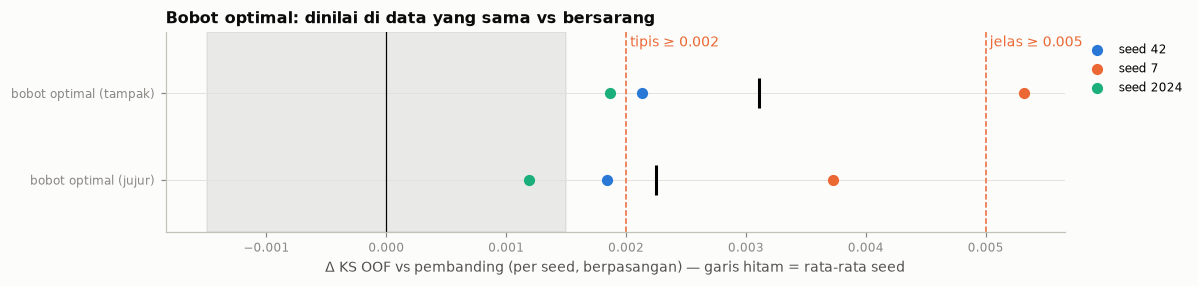

In [9]:
M.plot_paired_deltas(CMP, ["bobot optimal (tampak)", "bobot optimal (jujur)"], noise=0.0015,
                     title="Bobot optimal: dinilai di data yang sama vs bersarang")

**Cara membaca:** selisih antara "tampak" dan "jujur" adalah besarnya *overfitting* bobot. Ada dua tanda bahwa bobot optimal hanya mengejar noise:
1. Bobot di tabel per fold berubah-ubah drastis.
2. Δ "jujur" jauh di bawah Δ "tampak".

Kalau itu terjadi, jangan percaya bobot optimal. Pakai rata-rata sederhana, atau tetap dengan model tunggal.

## 5. Keputusan & submission

Kandidat: semua rata-rata sederhana + bobot optimal versi **jujur**. Versi "tampak" tidak ikut karena angkanya optimistis. Kandidat dengan Δ terbesar dipilih, lalu harus lolos aturan keputusan.

In [10]:
CANDS = [n for n in BLENDS if n != "bobot optimal (tampak)"]
BEST = max(CANDS, key=lambda n: CMP[n]["delta_seed_mean"])
VERDICT = M.verdict(CMP[BEST], noise=0.0015)
print(f"Kandidat terbaik: {BEST} | Δ rata-rata seed {CMP[BEST]['delta_seed_mean']:+.4f} "
      f"| seed naik {CMP[BEST]['n_seed_positive']}/{len(SEEDS)} | keputusan: {VERDICT}")
if VERDICT in ("jelas", "tipis"):
    if BEST == "bobot optimal (jujur)":
        final = M.blend(RUNS, y, weights=W_IN, seeds=SEEDS)       # bobot final = optimum di seluruh OOF
    else:
        final = BLENDS[BEST]
    final.update(features=FEAT, params=final.get("weights", {}), best_iters=[0])
    M.save_run("ensemble_v1", train, test, final, extra=dict(blend=BEST, weights=final.get("weights"),
                                                             delta_vs_lgbm_tuned=CMP[BEST]["delta_oof"]))
    ss = pl.read_parquet(E.PQ_DIR / "sample_submission.parquet")
    M.make_submission(test["application_id"], final["test_pred"], ss, M.SUB_DIR / "sub_v4_ensemble.csv")
    r = np.corrcoef(M.rank01(final["test_pred"]), M.rank01(base["test_pred"]))[0, 1]
    print(f"Korelasi peringkat prediksi test ensemble vs lgbm_tuned: {r:.4f}")
else:
    print("Tidak ada ensemble yang lolos → submission utama tetap sub_v3_lgbm_tuned.csv")

Kandidat terbaik: semua (bobot sama) | Δ rata-rata seed +0.0029 | seed naik 3/3 | keputusan: tipis
✅ kolom tepat [application_id, default_probability]
✅ jumlah baris = sample_submission
✅ application_id unik
✅ semua ID test ada & tidak ada ID asing
✅ probabilitas finite
✅ probabilitas dalam [0, 1]
✅ prediksi tidak konstan
Tersimpan: d:\LOMBA\LOGIKA\submissions\sub_v4_ensemble.csv  (30,000 baris)
Korelasi peringkat prediksi test ensemble vs lgbm_tuned: 0.9977
